In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel(r"C:\Users\Siddarood\Downloads\stock_risk_prediction_dataset (1).xlsx") 
df.head()

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,peak,essential,low,overstock
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,peak,non-essential,high,overstock
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,off-peak,non-essential,high,overstock
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,off-peak,essential,low,overstock
4,476,57.33,9.39,312.64,1052.98,4.49,5.12,peak,essential,high,overstock


In [3]:
df.shape

(5000, 11)

In [4]:
df['season'].unique(),df['supplier_reliability'].unique(),df['stock_status'].unique(),df['item_category'].unique()

(array(['peak', 'off-peak'], dtype=object),
 array(['low', 'high'], dtype=object),
 array(['overstock', 'stockout'], dtype=object),
 array(['essential', 'non-essential'], dtype=object))

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   current_stock         5000 non-null   int64  
 1   avg_daily_demand      5000 non-null   float64
 2   lead_time_days        5000 non-null   float64
 3   reorder_point         5000 non-null   float64
 4   sales_last_30_days    5000 non-null   float64
 5   stock_turnover_ratio  5000 non-null   float64
 6   forecast_error        5000 non-null   float64
 7   season                5000 non-null   object 
 8   item_category         5000 non-null   object 
 9   supplier_reliability  5000 non-null   object 
 10  stock_status          5000 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 429.8+ KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.describe()

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,500.065800,49.901224,7.021084,350.825734,1494.494344,3.993402,-0.054578
std,99.647785,10.104358,1.997617,50.166808,295.012442,0.999404,5.129634
min,175.000000,10.780000,0.250000,157.180000,403.470000,0.550000,-22.330000
25%,434.000000,43.130000,5.680000,316.765000,1289.470000,3.300000,-3.540000
50%,501.000000,49.825000,7.020000,350.960000,1497.595000,4.000000,-0.120000
75%,566.000000,56.772500,8.350000,385.332500,1695.180000,4.680000,3.442500
max,892.000000,85.290000,13.860000,573.950000,2583.410000,7.690000,18.640000


In [9]:
col = df.columns

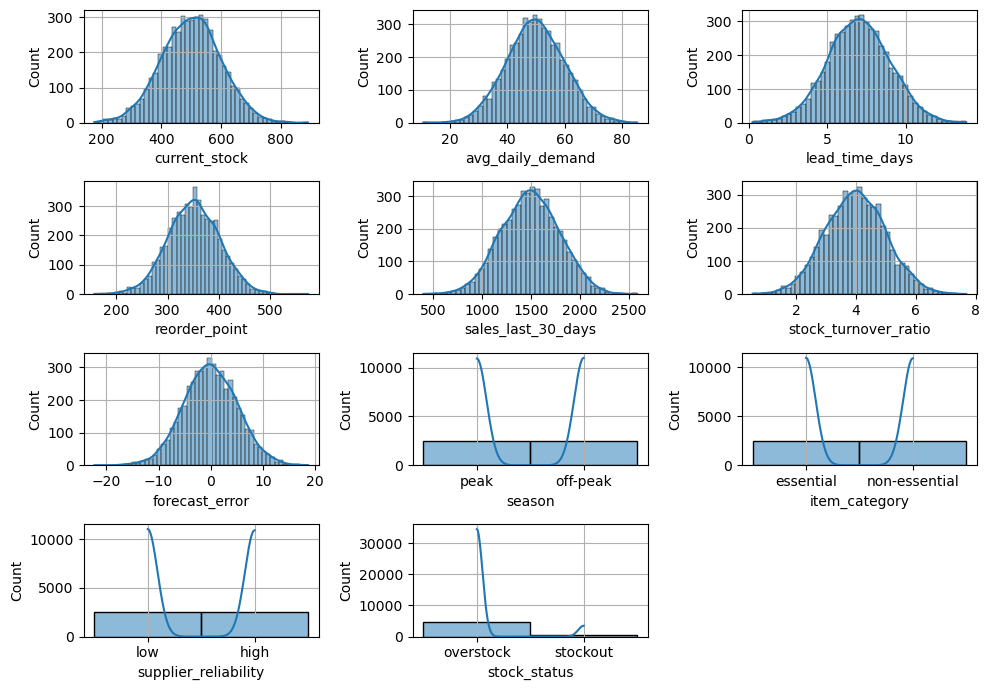

In [10]:
plt.figure(figsize=(10,7))
for i in range(len(col)):
    plt.subplot(4,3,i+1)
    sns.histplot(x=df[col[i]],kde=True)
    plt.grid()

plt.tight_layout()
plt.show()

In [11]:
numerical_col = df.select_dtypes(include=['number'])

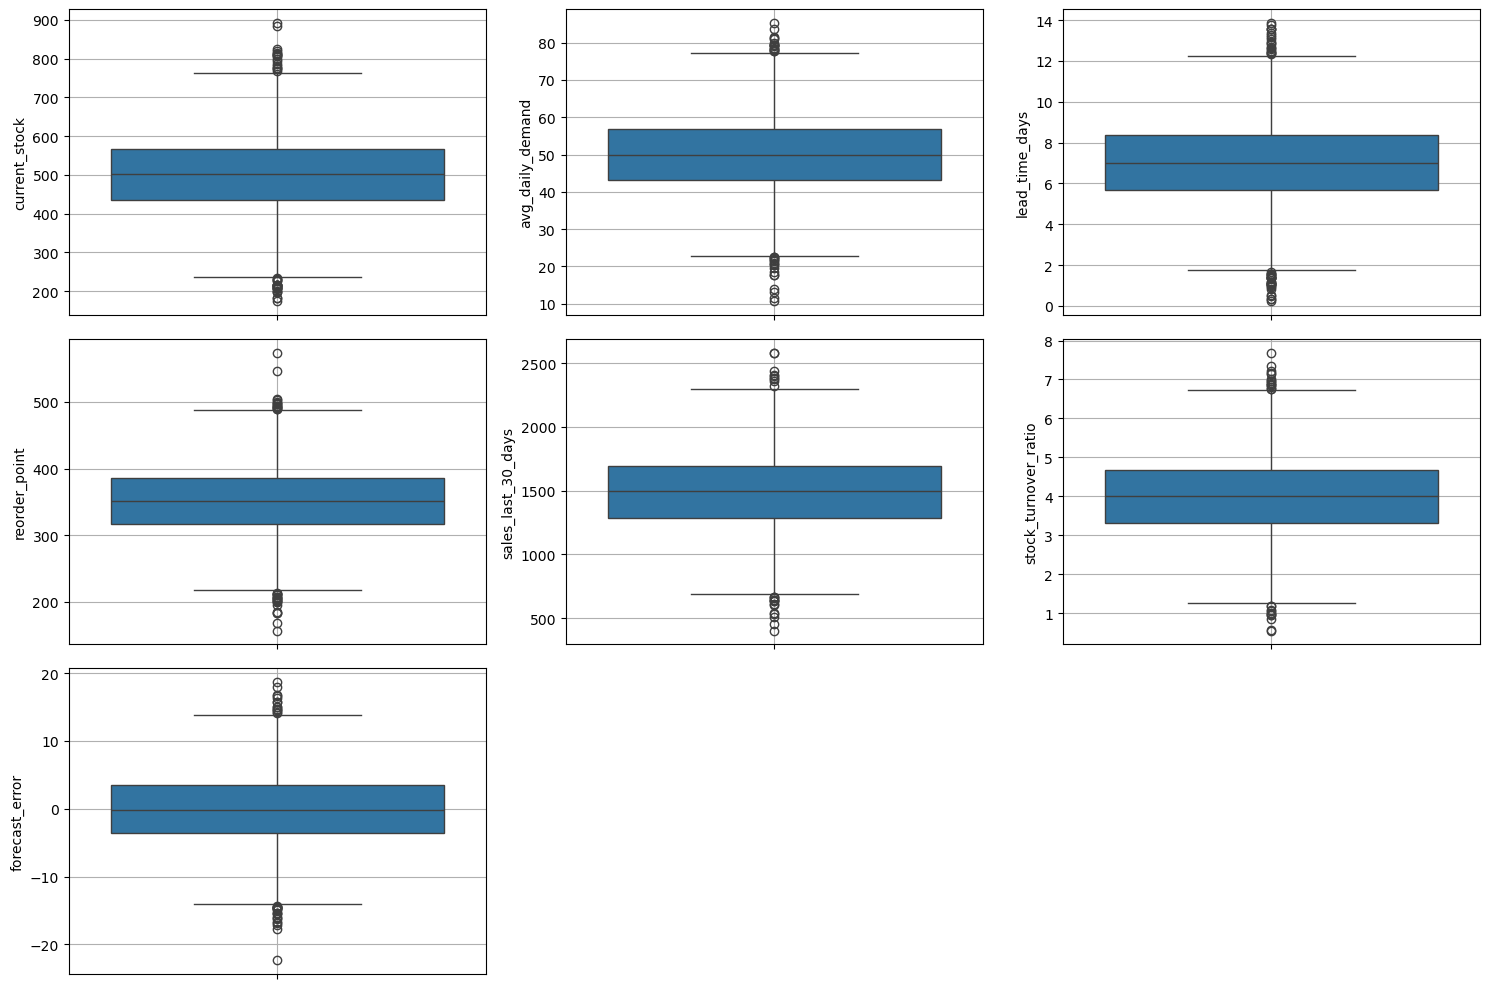

In [12]:
plt.figure(figsize=(15, 10))
for i, column in enumerate(numerical_col.columns):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(data=numerical_col[column])
    plt.grid()

plt.tight_layout()
plt.show()

<Axes: >

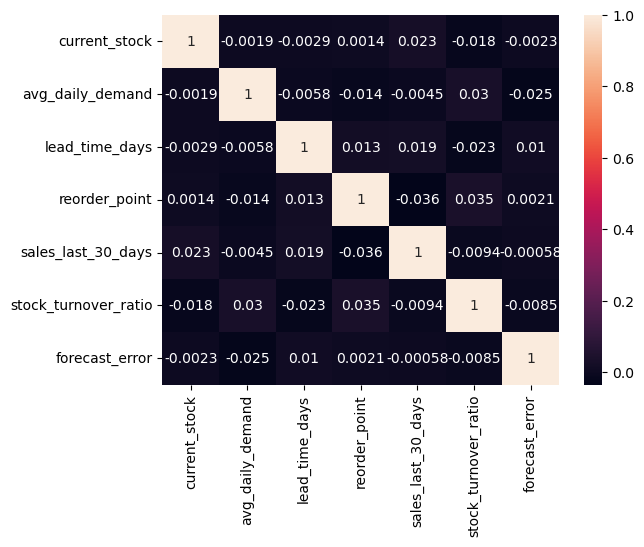

In [13]:
sns.heatmap(numerical_col.corr(),annot=True)

In [14]:
df_encoded = df.copy()

In [15]:
df_encoded['season']=df_encoded['season'].map({'peak':1,'off-peak':0})
df_encoded['item_category'] = df_encoded['item_category'].map({'essential':1,'non-essential':0})
df_encoded['supplier_reliability']=df_encoded['supplier_reliability'].map({'high':1,'low':0})
df_encoded['stock_status'] = df_encoded['stock_status'].map({'overstock':1,'stockout':0})

In [16]:
df_encoded.head()

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,stock_status
0,549,45.76,5.64,342.83,1604.49,4.17,-9.90,1,1,0,1
1,486,45.47,6.39,348.37,1585.00,4.01,-5.27,1,0,1,1
2,564,32.04,5.81,353.21,1219.04,3.57,-2.94,0,0,1,1
3,652,46.70,7.22,397.34,1673.88,4.00,0.75,0,1,0,1
4,476,57.33,9.39,312.64,1052.98,4.49,5.12,1,1,1,1


In [17]:
X = df_encoded.drop(columns=['stock_status'])
y = df_encoded['stock_status']

In [18]:
X.head()
y.head()

0    1
1    1
2    1
3    1
4    1
Name: stock_status, dtype: int64

In [44]:
from sklearn.model_selection import train_test_split

In [45]:
x_train,x_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)
print("Training features shape:", x_train.shape)
print("Testing features shape:", x_test.shape)

Training features shape: (4000, 10)
Testing features shape: (1000, 10)


In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()

In [48]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score,f1_score,r2_score,classification_report,confusion_matrix

In [50]:
Log_reg = LogisticRegression(class_weight='balanced',random_state=42)

In [51]:
Model_1_log = Log_reg.fit(x_train_scaled,y_train)
y_pred_log = Model_1_log.predict(x_test_scaled)

In [52]:
print("Accuracy:", accuracy_score(y_test,y_pred_log))
print("Preicision Score:", precision_score(y_test,y_pred_log))
print("Confusion Matrix:", confusion_matrix(y_test,y_pred_log))
print("\nClassification Report:\n",classification_report(y_test,y_pred_log))

Accuracy: 0.973
Preicision Score: 1.0
Confusion Matrix: [[ 91   0]
 [ 27 882]]

Classification Report:
               precision    recall  f1-score   support

           0       0.77      1.00      0.87        91
           1       1.00      0.97      0.98       909

    accuracy                           0.97      1000
   macro avg       0.89      0.99      0.93      1000
weighted avg       0.98      0.97      0.97      1000



In [53]:
Dec_Tree = DecisionTreeClassifier(class_weight='balanced',criterion='entropy',splitter='best',random_state=42)

In [54]:
Model_2_Dectree = Dec_Tree.fit(x_train_scaled,y_train)
y_pred_Dec = Model_2_Dectree.predict(x_test_scaled)

In [55]:
## Model Evaluation
print("Accuracy:", accuracy_score(y_test,y_pred_Dec))
print("Precision Score:", precision_score(y_test,y_pred_Dec))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred_Dec))
print("n\Classification Report:", classification_report(y_test,y_pred_Dec))

Accuracy: 0.994
Precision Score: 0.9988950276243094
Confusion Matrix: [[ 90   1]
 [  5 904]]
n\Classification Report:               precision    recall  f1-score   support

           0       0.95      0.99      0.97        91
           1       1.00      0.99      1.00       909

    accuracy                           0.99      1000
   macro avg       0.97      0.99      0.98      1000
weighted avg       0.99      0.99      0.99      1000



In [56]:
from sklearn.ensemble import RandomForestClassifier

In [57]:
rand_for = RandomForestClassifier(n_estimators=20,max_features='sqrt',random_state=42)

In [58]:
Model_3_rand_for = rand_for.fit(x_train_scaled,y_train)
y_pred_random = Model_3_rand_for.predict(x_test_scaled)

In [59]:
print("Accuracy Score:", accuracy_score(y_test,y_pred_random))
print("Precision Score:", precision_score(y_test,y_pred_random))
print("Confusion Matrix:", confusion_matrix(y_test,y_pred_random))
print("Classification Report:", classification_report(y_test,y_pred_random))

Accuracy Score: 0.993
Precision Score: 0.9945175438596491
Confusion Matrix: [[ 86   5]
 [  2 907]]
Classification Report:               precision    recall  f1-score   support

           0       0.98      0.95      0.96        91
           1       0.99      1.00      1.00       909

    accuracy                           0.99      1000
   macro avg       0.99      0.97      0.98      1000
weighted avg       0.99      0.99      0.99      1000



In [60]:
!pip install xgboost

In [61]:
import xgboost as xgb

In [62]:
XGboost = xgb.XGBClassifier(n_estimators=50,learning_rate=0.5,reg_alpha=10,reg_lamda=10)

In [63]:
Model_4_XGB = XGboost.fit(x_train_scaled,y_train)
y_pred_XGB = Model_4_XGB.predict(x_test_scaled)

In [64]:
print("Accuracy:", accuracy_score(y_test,y_pred_XGB))
print("Precision:", precision_score(y_test,y_pred_XGB))
print("R2_score:", r2_score(y_test,y_pred_XGB))
print("Consufion Matrix:", confusion_matrix(y_test,y_pred_XGB))
print("Classification_Report:", classification_report(y_test,y_pred_XGB))

Accuracy: 0.992
Precision: 0.9955995599559956
R2_score: 0.9032870319999033
Consufion Matrix: [[ 87   4]
 [  4 905]]
Classification_Report:               precision    recall  f1-score   support

           0       0.96      0.96      0.96        91
           1       1.00      1.00      1.00       909

    accuracy                           0.99      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.99      0.99      0.99      1000



In [65]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import joblib

model = joblib.load('logistic_regression_model.pkl')
scaler = joblib.load('scaler.pkl')
feature_columns = joblib.load('features_columns.pkl')

st.title("Inventory Risk Prediction App")
st.write("Predict whether an inventory item is at risk of Stockout or Overstock using Logistic Regression.")

st.subheader("Enter Inventory Parameters")

# Inputs matching our daily data
current_stock = st.number_input("Current Stock", min_value=0.0, max_value=10000.0, value=501.0, step=1.0)
avg_daily_demand = st.number_input("Average Daily Demand", min_value=0.10, max_value=10000.00,value=49.83, step=0.1)
lead_time_days = st.number_input("Lead Time (Days)", min_value=0.25, max_value=20.00, value=7.02, step=0.1)
reorder_point = st.number_input("Reorder Point", min_value=150.18, max_value=1000.95, value=350.96, step=0.1)
sales_last_30_days = st.number_input("Sales Last 30 Days", min_value=400.47, max_value=5000.41, value=1497.60, step=1.0)
stock_turnover_ratio = st.number_input("Stock Turnover Ratio", min_value=0.10, max_value=10, value=4.00, step=0.01)
forecast_error = st.number_input("Forecast Error", min_value=-100.0, max_value=100.00, value=-0.12, step=0.01)

# Categorical inputs matching the manual binary mapping
season = st.selectbox("Season", options=["Off-Peak (0)", "Peak (1)"])
item_category = st.selectbox("Item Category", options=["Non-Essential (0)", "Essential (1)"])
supplier_reliability = st.selectbox("Supplier Reliability", options=["Low/Medium (0)", "High (1)"])

# Converstion of categorical selections to numerical values
season_val = 1 if "Peak (1)" in season else 0
category_val = 1 if "Essential (1)" in item_category else 0
supplier_val = 1 if "High (1)" in supplier_reliability else 0

if st.button("Predict Stock Status"):
    input_data = {
        'current_stock': [current_stock],
        'avg_daily_demand': [avg_daily_demand],
        'lead_time_days': [lead_time_days],
        'reorder_point': [reorder_point],
        'sales_last_30_days': [sales_last_30_days],
        'stock_turnover_ratio': [stock_turnover_ratio],
        'forecast_error': [forecast_error],
        'season': [season_val],
        'item_category': [category_val],
        'supplier_reliability': [supplier_val]
    }
    
    input_df = pd.DataFrame(input_data)
    input_df = input_df[feature_columns]
    
    input_scaled = scaler.transform(input_df)
    prediction = model.predict(input_scaled)
    probability = model.predict_proba(input_scaled)
    
    st.subheader("Prediction Result:")
    if prediction[0] == 1:
        st.success("Status: **Overstock**")
    else:
        st.error("Status: **Stockout Risk**")
        
    st.write(f"Confidence: {np.max(probability)*100:.2f}%")

pip freeze > requirements.txt

Overwriting app.py
